# Testing pulling data for active/nonactive gages

In [4]:
import pandas as pd
import geopandas as gpd
import requests
import subprocess
from pathlib import Path
import shutil
import time
from io import StringIO
import folium
from IPython.display import display
import contextily as ctx
import matplotlib.pyplot as plt
import pprint
import duckdb
import json
from shapely.geometry import Polygon

#### Inspecting nwis 30_data_summarizes github

Need to find where they are pulling sources for this .R code https://github.com/DOI-USGS/national-flow-observations/blob/main/30_data_summarize/src/summarize_active_flow_gages.R 

gage activity history (Pulls gage ID +years active (using usgs classification by days active))

gage location (ID+lat,lon,state)

In [5]:
url = "https://api.github.com/repos/DOI-USGS/national-flow-observations/contents/30_data_summarize.yml"

response = requests.get(url, timeout=30)


#### KEY FILES IDENTIFIED AS:
##### active_flow_gages_wy.rds = Active gage IDs grouped by water year
##### active_flow_gages_summary_wy.rds = Summary of each gage's active years and gaps
##### observation_summary.rds = A separate observation summary that may help investigate data coverage

##### and min days active defined as 335 days/year

##### NEXT DOWNLOADING THESE THREE FILES TO data/raw FOLDER

##### -only have summary_wy.rds file from gages github
##### the other two are stored as .rd.ind (indicator files in nwis github. (need to find original source))

In [6]:
project_folder = Path.cwd().parent
raw_folder = project_folder / "data" / "raw"
raw_folder.mkdir(parents=True, exist_ok=True)

files = {
    "active_flow_gages_summary_wy.rds":
        "https://raw.githubusercontent.com/DOI-USGS/gages-through-the-ages/main/gage_timeseries_gif/active_flow_gages_summary_wy.rds",
    "active_flow_gages_wy.rds":
        "https://raw.githubusercontent.com/DOI-USGS/gages-through-the-ages/main/gage_timeseries_gif/active_flow_gages_wy.rds",
}

#### active_flow_gages_wy.rds not available
##### Going to inspect the summary file and then search for this file if its needed

##### Reading active_flow_gages_summary_wy.rds using R and export as csv for to python to inspect (stored in data/intermediate)

In [7]:
project_folder = Path.cwd().parent
rds_path = project_folder / "data" / "raw" / "active_flow_gages_summary_wy.rds"
csv_path = project_folder / "data" / "intermediate" / "active_flow_gages_summary_wy.csv"
script_path = project_folder / "data" / "intermediate" / "read_gage_summary.R"

r_script = f'''
data <- readRDS("{rds_path.as_posix()}")

collapse_list <- function(x) {{
  if (is.null(x) || length(x) == 0 || all(is.na(x))) {{
    return(NA_character_)
  }}
  paste(x[!is.na(x)], collapse = ";")
}}

data$which_years_active <- vapply(
  data$which_years_active, collapse_list, character(1)
)

data$gap_years <- vapply(
  data$gap_years, collapse_list, character(1)
)

write.csv(data, "{csv_path.as_posix()}", row.names = FALSE)
cat("Exported rows:", nrow(data), "\\\\n")
cat("Exported columns:", ncol(data), "\\\\n")
'''

script_path.write_text(r_script, encoding="utf-8")

result = subprocess.run(
    ["Rscript", str(script_path)],
    capture_output=True,
    text=True
)


#### Inspecting the summary csv

In [8]:
project_folder = Path.cwd().parent
csv_path = project_folder / "data" / "intermediate" / "active_flow_gages_summary_wy.csv"

gages = pd.read_csv(csv_path)

print("Rows and columns:", gages.shape)
print("Column names:")
print(gages.columns.tolist())

print("First 5 rows:")
display(gages.head())

print("Data types:")
print(gages.dtypes)


Rows and columns: (23242, 6)
Column names:
['site', 'n_years_active', 'earliest_active_year', 'which_years_active', 'any_gaps', 'gap_years']
First 5 rows:


,site,n_years_active,earliest_active_year,which_years_active,any_gaps,gap_years
0,7010000,159,1863,1863;1864;1865;1866;1867;1868;1869;1870;1871;1...,False,NaN
1,5420500,148,1874,1874;1875;1876;1877;1878;1879;1880;1881;1882;1...,False,NaN
2,3568000,134,1875,1875;1876;1877;1878;1879;1880;1881;1882;1883;1...,False,NaN
3,3193000,144,1878,1878;1879;1880;1881;1882;1883;1884;1885;1886;1...,False,NaN
4,5474500,143,1879,1879;1880;1881;1882;1883;1884;1885;1886;1887;1...,False,NaN


Data types:
site                    int64
n_years_active          int64
earliest_active_year    int64
which_years_active        str
any_gaps                 bool
gap_years                 str
dtype: object


#### NOW TESTING USGS WATER DATA API LOCATIONS SOURCE https://api.waterdata.usgs.gov/ogcapi/v1/openapi#/monitoring-locations/getMonitoring-locationsFeatures

In [9]:
url = (
    "https://api.waterdata.usgs.gov/ogcapi/v1/"
    "collections/monitoring-locations/items"
)


#### seeing if water data usgs api has better location matches than GAGES 3

In [10]:
project_dir = Path.cwd().parent
activity_file = project_dir / "data" / "intermediate" / "active_flow_gages_summary_wy.csv"

# Load the activity summary preserving station IDs as text
activity = pd.read_csv(activity_file, dtype={"site": str})
activity["site"] = activity["site"].str.strip()

# Standardize IDs for the USGS API
site_ids = activity["site"].dropna().unique().tolist()
site_ids = [s.removeprefix("USGS-").strip() for s in site_ids if s.strip()]

print(f"Activity-summary stations to look up: {len(site_ids):,}")

# USGS Water Data API monitoring locations
url = "https://api.waterdata.usgs.gov/ogcapi/v0/collections/monitoring-locations/items"

found_records = []
failed_batches = []
batch_size = 100

for start in range(0, len(site_ids), batch_size):
    batch = site_ids[start:start + batch_size]

    params = {
        "monitoring_location_id": ",".join(
            s if s.startswith("USGS-") else f"USGS-{s}" for s in batch
        ),
        "limit": batch_size
    }

    try:
        response = requests.get(url, params=params, timeout=60)

        if response.status_code == 200:
            data = response.json()
            features = data.get("features", [])
            found_records.extend(features)
        else:
            failed_batches.append({
                "batch_start": start,
                "status_code": response.status_code,
                "message": response.text[:200]
            })

    except requests.RequestException as e:
        failed_batches.append({
            "batch_start": start,
            "status_code": "Request error",
            "message": str(e)[:200]
        })

    if (start // batch_size + 1) % 20 == 0:
        print(f"Processed {min(start + batch_size, len(site_ids)):,} of {len(site_ids):,}")

    time.sleep(0.1)

print(f"Unique activity-summary IDs: {len(site_ids):,}")
print(f"Location records returned: {len(found_records):,}")
print(f"Failed batches: {len(failed_batches):,}")


Activity-summary stations to look up: 23,242
Processed 2,000 of 23,242
Processed 4,000 of 23,242
Processed 6,000 of 23,242
Processed 8,000 of 23,242
Processed 10,000 of 23,242
Processed 12,000 of 23,242
Processed 14,000 of 23,242
Processed 16,000 of 23,242
Processed 18,000 of 23,242
Processed 20,000 of 23,242
Processed 22,000 of 23,242
Unique activity-summary IDs: 23,242
Location records returned: 0
Failed batches: 233


#### GET API KEY FOR USGS

In [11]:
api_key = "mPgnnQwJbw7q6PW6rqQpkpBCGzMLwqdjcCLBrnw8"

test_ids = activity["site"].dropna().astype(str).str.strip().head(10).tolist()

params = {
    "id": ",".join(
        s if s.startswith("USGS-") else f"USGS-{s}"
        for s in test_ids
    ),
    "limit": 100
}

url = "https://api.waterdata.usgs.gov/ogcapi/v0/collections/monitoring-locations/items"

response = requests.get(
    url,
    params=params,
    headers={"X-Api-Key": api_key},
    timeout=60
)


#### Matching locations to usgs water data in batches CREATING LOCATIONS FILE

In [12]:
project_dir = Path.cwd().parent
output_dir = project_dir / "data" / "intermediate"
output_dir.mkdir(parents=True, exist_ok=True)

locations_file = output_dir / "usgs_api_locations.csv"
failed_file = output_dir / "usgs_api_failed_batches.csv"
missing_file = output_dir / "activity_summary_ids_missing_api.csv"

# Get all unique station IDs from the activity summary
site_ids = (
    activity["site"]
    .dropna()
    .astype(str)
    .str.strip()
    .drop_duplicates()
    .tolist()
)

site_ids = [
    s.removeprefix("USGS-")
    for s in site_ids
    if s and s.lower() != "nan"
]

url = "https://api.waterdata.usgs.gov/ogcapi/v0/collections/monitoring-locations/items"
headers = {"X-Api-Key": api_key}
batch_size = 100

location_records = []
failed_batches = []

for start in range(0, len(site_ids), batch_size):
    batch = site_ids[start:start + batch_size]

    params = {
        "id": ",".join(f"USGS-{s}" for s in batch),
        "limit": batch_size
    }

    success = False

    
    for attempt in range(3):
        try:
            response = requests.get(
                url, params=params, headers=headers, timeout=60
            )

            if response.status_code == 200:
                features = response.json().get("features", [])

                for feature in features:
                    properties = feature.get("properties", {})
                    coordinates = (feature.get("geometry") or {}).get(
                        "coordinates", []
                    )

                    location_records.append({
                        "site": str(
                            properties.get("monitoring_location_number")
                            or properties.get("id", "")
                        ).removeprefix("USGS-"),
                        "api_id": properties.get("id"),
                        "station_name": properties.get(
                            "monitoring_location_name"
                        ),
                        "state_name": properties.get("state_name"),
                        "latitude": (
                            coordinates[1] if len(coordinates) >= 2 else None
                        ),
                        "longitude": (
                            coordinates[0] if len(coordinates) >= 2 else None
                        )
                    })

                success = True
                break

            if response.status_code == 429 or response.status_code >= 500:
                time.sleep(2 ** (attempt + 1))
            else:
                break

        except requests.RequestException:
            time.sleep(2 ** (attempt + 1))

    if not success:
        failed_batches.append({
            "batch_start": start,
            "batch_size": len(batch),
            "status_code": (
                response.status_code if "response" in locals() else None
            ),
            "site_ids": ";".join(batch)
        })

    # checkpoints every 10 batches
    if (start // batch_size + 1) % 10 == 0:
        pd.DataFrame(location_records).drop_duplicates(
            subset="site"
        ).to_csv(locations_file, index=False)

        pd.DataFrame(failed_batches).to_csv(failed_file, index=False)

        print(
            f"Processed {min(start + batch_size, len(site_ids)):,}"
            f" / {len(site_ids):,} station IDs; "
            f"locations returned: {len(location_records):,}; "
            f"failed batches: {len(failed_batches)}"
        )

    time.sleep(0.2)


locations = pd.DataFrame(location_records)

if not locations.empty:
    locations = locations.drop_duplicates(subset="site")
    locations.to_csv(locations_file, index=False)

pd.DataFrame(failed_batches).to_csv(failed_file, index=False)


found_ids = set(locations["site"]) if not locations.empty else set()
missing_ids = sorted(set(site_ids) - found_ids)

pd.DataFrame({"site": missing_ids}).to_csv(missing_file, index=False)


print(f"Activity-summary stations: {len(site_ids):,}")
print(f"Unique locations returned: {len(found_ids):,}")
print(f"Stations without returned locations: {len(missing_ids):,}")
print(f"Failed batches: {len(failed_batches):,}")
print(f"Locations saved to: {locations_file}")
print(f"Missing IDs saved to: {missing_file}")
print(f"Failed batches saved to: {failed_file}")

Processed 1,000 / 23,242 station IDs; locations returned: 1,000; failed batches: 0
Processed 2,000 / 23,242 station IDs; locations returned: 2,000; failed batches: 0
Processed 3,000 / 23,242 station IDs; locations returned: 3,000; failed batches: 0
Processed 4,000 / 23,242 station IDs; locations returned: 4,000; failed batches: 0
Processed 5,000 / 23,242 station IDs; locations returned: 5,000; failed batches: 0
Processed 6,000 / 23,242 station IDs; locations returned: 6,000; failed batches: 0
Processed 7,000 / 23,242 station IDs; locations returned: 7,000; failed batches: 0
Processed 8,000 / 23,242 station IDs; locations returned: 8,000; failed batches: 0
Processed 9,000 / 23,242 station IDs; locations returned: 9,000; failed batches: 0
Processed 10,000 / 23,242 station IDs; locations returned: 10,000; failed batches: 0
Processed 11,000 / 23,242 station IDs; locations returned: 11,000; failed batches: 0
Processed 12,000 / 23,242 station IDs; locations returned: 12,000; failed batches: 

#### Join activity summary to location data (made in previous step)

In [13]:
project_dir = Path.cwd().parent
data_dir = project_dir / "data" / "intermediate"

activity_file = data_dir / "active_flow_gages_summary_wy.csv"
locations_file = data_dir / "usgs_api_locations.csv"


activity = pd.read_csv(activity_file, dtype={"site": str})
locations = pd.read_csv(locations_file, dtype={"site": str})


activity["site"] = activity["site"].str.strip().str.removeprefix("USGS-")
locations["site"] = locations["site"].str.strip().str.removeprefix("USGS-")

# Check for duplicate IDs before joining
print("Activity rows:", len(activity))
print("Unique activity IDs:", activity["site"].nunique())
print("Location rows:", len(locations))
print("Unique location IDs:", locations["site"].nunique())

# Keep every activity-summary station
master = activity.merge(
    locations,
    on="site",
    how="left",
    validate="one_to_one",
    indicator=True
)

# Identify stations with missing locations or coordinates
no_location = master["_merge"] == "left_only"
no_coordinates = master["latitude"].isna() | master["longitude"].isna()

master["location_found"] = ~no_location
master["coordinates_available"] = ~no_coordinates

# Save the joined master table
master_file = data_dir / "gages_activity_with_api_locations.csv"
master.drop(columns="_merge").to_csv(master_file, index=False)



Activity rows: 23242
Unique activity IDs: 23242
Location rows: 23241
Unique location IDs: 23241


## gages_activity_with_api_location.csv is the activity table with coordinates 

#### Missing coordinates for 4 stations and missing api match for 1 station
###### Inspecting these gage sites

In [14]:
missing_sites = ["11516100", "09489082", "421247071470201", "422108071052501"]

url = "https://waterservices.usgs.gov/nwis/site/"

params = {
    "format": "rdb",
    "sites": ",".join(missing_sites),
    "siteOutput": "expanded"
}

response = requests.get(url, params=params, timeout=60)

print("URL:", response.url)

if response.status_code == 200:
    lines = [
        line for line in response.text.splitlines()
        if not line.startswith("#")
        and line.strip()
    ]

    print("First lines returned:")
    print("".join(lines[:8]))

    # RDB files have two header lines before the data
    from io import StringIO

    rdb_lines = [
        line for line in response.text.splitlines()
        if not line.startswith("#") and line.strip()
    ]

    if len(rdb_lines) >= 3:
        site_data = pd.read_csv(
            StringIO("".join(rdb_lines)),
            sep="\t",
            dtype=str,
            skiprows=[1]
        )

        print("Columns containing coordinates:")
        print([
            col for col in site_data.columns
            if "lat" in col.lower() or "long" in col.lower()
        ])

        display(site_data[[
            col for col in [
                "site_no",
                "station_nm",
                "dec_lat_va",
                "dec_long_va"
            ]
            if col in site_data.columns
        ]])
else:
    print(response.text[:1000])

URL: https://waterservices.usgs.gov/nwis/site/?format=rdb&sites=11516100%2C09489082%2C421247071470201%2C422108071052501&siteOutput=expanded
First lines returned:
agency_cd	site_no	station_nm	site_tp_cd	lat_va	long_va	dec_lat_va	dec_long_va	coord_meth_cd	coord_acy_cd	coord_datum_cd	dec_coord_datum_cd	district_cd	state_cd	county_cd	country_cd	land_net_ds	map_nm	map_scale_fc	alt_va	alt_meth_cd	alt_acy_va	alt_datum_cd	huc_cd	basin_cd	topo_cd	instruments_cd	construction_dt	inventory_dt	drain_area_va	contrib_drain_area_va	tz_cd	local_time_fg	reliability_cd	gw_file_cd	nat_aqfr_cd	aqfr_cd	aqfr_type_cd	well_depth_va	hole_depth_va	depth_src_cd	project_no5s	15s	50s	7s	16s	16s	16s	16s	1s	1s	10s	10s	3s	2s	3s	2s	23s	20s	7s	8s	1s	3s	10s	16s	2s	1s	30s	8s	8s	8s	8s	6s	1s	1s	30s	10s	8s	1s	8s	8s	1s	12sUSFS	09489082	NORTH FORK THOMAS CREEK NEAR ALPINE, AZ	ST	334030.1	1091612.4	33.67502778	-109.2701111	N	S	NAD83	NAD83	04	04	011	US				 8380.	M	 20	NGVD29	15060101			YNNNYNNNNNYNNYNNNNNNNNNNNNNNNN			.73		MST	N

,site_no,station_nm,dec_lat_va,dec_long_va


#### ^ only found 09489082 site coordinates, need to find another source for the other three missing gages (https://waterservices.usgs.gov/nwis/site/?format=rdb&sites=11516100%2C09489082%2C421247071470201%2C422108071052501&siteOutput=expanded)

###### moving on without these three gages

### amending the found coordinates for 09489082 to gages_activity_with_api_loc

In [15]:
project = Path(
    "/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research"
)

input_file = (
    project / "data" / "intermediate" /
    "gages_activity_with_api_locations.csv"
)

output_file = (
    project / "data" / "intermediate" /
    "gages_activity_with_api_locations_recovered.csv"
)

df = pd.read_csv(
    input_file,
    dtype={"site": str}
)

df["site"] = df["site"].astype(str).str.strip()

print("Original rows:", len(df))
print("Unique gages:", df["site"].nunique())

# RECOVERED INFORMATION FOR 09489082

recovered_site = "09489082"

match = df["site"] == recovered_site

print("Rows matching 09489082:", match.sum())

# Update all recovered information
df.loc[match, "station_name"] = (
    "NORTH FORK THOMAS CREEK NEAR ALPINE, AZ"
)

df.loc[match, "state_name"] = "Arizona"

df.loc[match, "latitude"] = 33.67502778

df.loc[match, "longitude"] = -109.2701111


display(
    df.loc[
        match,
        [
            "site",
            "station_name",
            "state_name",
            "latitude",
            "longitude"
        ]
    ]
)

df.to_csv(
    output_file,
    index=False
)
#CHECK
with_coordinates = (
    df["latitude"].notna() &
    df["longitude"].notna()
)


Original rows: 23242
Unique gages: 23242
Rows matching 09489082: 1


,site,station_name,state_name,latitude,longitude
16580,09489082,"NORTH FORK THOMAS CREEK NEAR ALPINE, AZ",Arizona,33.675028,-109.270111


#### Now gages_activity_with_api_locations_recovered.csv has activity and coordinates with 09489082s coordinates

## Mapping layer for given state given year

State: Missouri
Total gages in Missouri: 397
Missouri gages in 2000: 297
Sample:


,site,station_name,latitude,longitude,year,status
0,07010000,"Mississippi River at St. Louis, MO",38.629000,-90.179778,2000,Active
1,06933500,"Gasconade River at Jerome, MO",37.929917,-91.977333,2000,Active
2,07019000,"Meramec River near Eureka, MO",38.505139,-90.590167,2000,Active
3,06928500,"Gasconade River near Waynesville, MO",37.872262,-92.227113,2000,Inactive
4,06920500,"Osage River at Osceola, MO",38.062252,-93.693821,2000,Inactive
5,07021000,"Castor River at Zalma, MO",37.146639,-90.075500,2000,Inactive
6,06897500,"Grand River near Gallatin, MO",39.926952,-93.942722,2000,Active
7,06900000,"Medicine Creek near Galt, MO",40.129744,-93.362542,2000,Inactive
8,06901000,"Locust Creek near Milan, MO",40.183352,-93.170487,2000,Inactive
9,06905000,"Chariton River at Elmer, MO",39.952925,-92.666006,2000,Inactive


Gages with coordinates: 297


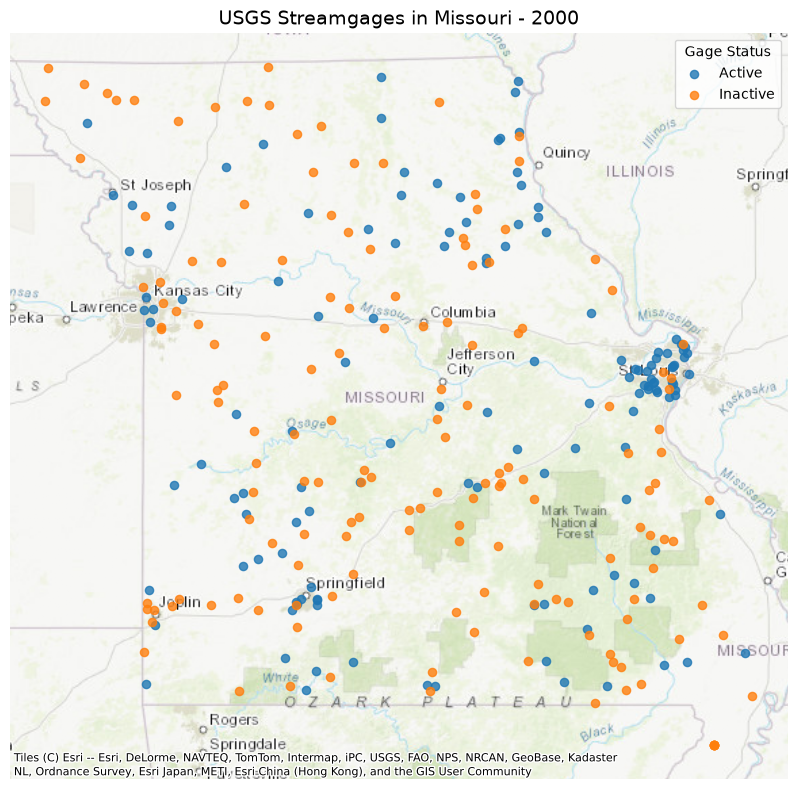

In [16]:
#interchangable
state = "Missouri"
year = 2000

#From previous 
input_file = (
    "/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research/"
    "data/intermediate/gages_activity_with_api_locations_recovered.csv"
)
df = pd.read_csv(input_file, dtype={"site": str})

active_rows = []

for _, row in df.iterrows():

    years = str(row["which_years_active"])

    if years in ["nan", "", "None"]:
        continue

    for y in years.split(";"):

        try:
            y = int(y)

            active_rows.append({
                "site": row["site"],
                "station_name": row["station_name"],
                "state_name": row["state_name"],
                "latitude": row["latitude"],
                "longitude": row["longitude"],
                "year": y,
                "status": "Active"
            })

        except ValueError:
            pass

active_df = pd.DataFrame(active_rows)

# GET GAGES
state_gages = df[
    df["state_name"].astype(str).str.strip() == state
].copy()

print(f"State: {state}")
print(f"Total gages in {state}: {len(state_gages)}")


# GET GAGES ACTIVE

active_this_year = active_df[
    (active_df["state_name"] == state) &
    (active_df["year"] == year)
].copy()

# Determine each gage's first active year
first_year = (
    active_df
    .groupby("site")["year"]
    .min()
    .reset_index()
    .rename(columns={"year": "first_active_year"})
)

state_gages = state_gages.merge(
    first_year,
    on="site",
    how="left"
)

# Gages active in selected year
active_sites = set(active_this_year["site"])

# Keep only gages that had started operating by this year
state_gages = state_gages[
    state_gages["first_active_year"].notna() &
    (state_gages["first_active_year"] <= year)
].copy()

state_gages["status"] = state_gages["site"].apply(
    lambda x: "Active" if x in active_sites else "Inactive"
)

state_gages["year"] = year

# REMOVE DUPLICATES
state_year = state_gages.drop_duplicates(
    subset=["site"]
).copy()


# results table

print(f"{state} gages in {year}: {len(state_year)}")

print("Sample:")
display(
    state_year[
        [
            "site",
            "station_name",
            "latitude",
            "longitude",
            "year",
            "status"
        ]
    ].head(20)
)

# REMOVE GAGES WITHOUT COORDINATES

map_df = state_year.dropna(
    subset=["latitude", "longitude"]
).copy()

print(f"Gages with coordinates: {len(map_df)}")  # to be compared with gages acitve in x year


#Map

# Convert gages to GeoDataFrame
gdf = gpd.GeoDataFrame(
    map_df,
    geometry=gpd.points_from_xy(
        map_df["longitude"],
        map_df["latitude"]
    ),
    crs="EPSG:4326"
)

# Web basemaps use Web Mercator
gdf = gdf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 8))

# Plot Active
active = gdf[gdf["status"] == "Active"]

active.plot(
    ax=ax,
    markersize=35,
    label="Active",
    alpha=0.8
)

# Plot Inactive
inactive = gdf[gdf["status"] == "Inactive"]

inactive.plot(
    ax=ax,
    markersize=35,
    label="Inactive",
    alpha=0.8
)

# Add basemap
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldTopoMap
)

ax.set_title(
    f"USGS Streamgages in {state} - {year}",
    fontsize=14
)

ax.set_axis_off()

ax.legend(title="Gage Status")

plt.tight_layout()
plt.show()


### How to export as spatial dataset (how should the activity data be organized per vector point)

# Testing pulling data for Disaster Declerations

### inspecting fema disaster declerations open v2 csv https://www.fema.gov/openfema-data-page/disaster-declarations-summaries-v2

In [17]:
url = "https://www.fema.gov/api/open/v2/DisasterDeclarationsSummaries"

params = {
    "$allrecords": "true",
    "$format": "json"
}

response = requests.get(
    url,
    params=params,
    timeout=180
)


data = response.json()

# Get the records returned by FEMA
fema = pd.DataFrame(
    data.get("DisasterDeclarationsSummaries", [])
)

print("Records returned:", len(fema))

if not fema.empty:
    print("Unique disaster numbers:", fema["disasterNumber"].nunique())
    print("Incident types:")
    print(fema["incidentType"].value_counts())

    # Keep flood declarations
    floods = fema[
        fema["incidentType"].astype(str).str.strip().str.lower()
        == "flood"
    ].copy()

    floods["declarationDate"] = pd.to_datetime(
        floods["declarationDate"],
        errors="coerce",
        utc=True
    )

    floods["year"] = floods["declarationDate"].dt.year

    # One row per disaster number and state
    floods = floods.drop_duplicates(
        subset=["disasterNumber", "state"]
    )

    print("Unique flood disasters:", len(floods))
    display(
        floods[
            [
                "disasterNumber",
                "state",
                "year",
                "declarationDate",
                "incidentType",
                "declarationTitle"
            ]
        ].head(20)
    )

Records returned: 70581
Unique disaster numbers: 5285
Incident types:
incidentType
Severe Storm           19493
Hurricane              13735
Flood                  11516
Biological              7857
Fire                    3957
Snowstorm               3707
Severe Ice Storm        2956
Tornado                 1627
Winter Storm            1378
Drought                 1292
Tropical Storm          1199
Coastal Storm            637
Other                    315
Freezing                 301
Earthquake               229
Typhoon                  136
Volcanic Eruption         51
Straight-Line Winds       49
Mud/Landslide             44
Fishing Losses            42
Dam/Levee Break           13
Chemical                  10
Toxic Substances           9
Tsunami                    9
Tropical Depression        7
Human Cause                7
Terrorist                  5
Name: count, dtype: int64
Unique flood disasters: 930


,disasterNumber,state,year,declarationDate,incidentType,declarationTitle
866,4945,OH,2026,2026-10-02 00:00:00+00:00,Flood,"SEVERE STORMS, STRAIGHT-LINE WINDS, TORNADOES,..."
976,4935,TX,2026,2026-09-01 00:00:00+00:00,Flood,"SEVERE STORMS, STRAIGHT-LINE WINDS, TORNADOES,..."
1006,4933,IN,2026,2026-08-25 00:00:00+00:00,Flood,"SEVERE STORMS, STRAIGHT-LINE WINDS, TORNADOES,..."
1104,4925,MI,2026,2026-06-30 00:00:00+00:00,Flood,"SEVERE STORMS, TORNADOES, AND FLOODING"
1151,4923,WI,2026,2026-06-30 00:00:00+00:00,Flood,"SEVERE STORMS, TORNADOES, AND FLOODING"
1217,4912,AK,2026,2026-05-29 00:00:00+00:00,Flood,"SEVERE STORMS, FLOODING, AND REMNANTS OF TYPHO..."
1224,4909,HI,2026,2026-04-07 00:00:00+00:00,Flood,"SEVERE STORMS, FLOODING, LANDSLIDES, AND MUDSL..."
1241,4906,WA,2026,2026-04-07 00:00:00+00:00,Flood,"SEVERE STORMS, STRAIGHT-LINE WINDS, FLOODING, ..."
1336,4901,MT,2026,2026-04-07 00:00:00+00:00,Flood,SEVERE STORMS AND FLOODING
1565,4893,AK,2025,2025-10-22 00:00:00+00:00,Flood,"SEVERE STORMS, FLOODING, AND REMNANTS OF TYPHO..."


#### We want to filter to only floods

In [18]:
print(fema.columns.tolist())
print(fema["incidentType"].value_counts(dropna=False))

['femaDeclarationString', 'disasterNumber', 'state', 'declarationType', 'declarationDate', 'fyDeclared', 'incidentType', 'declarationTitle', 'ihProgramDeclared', 'iaProgramDeclared', 'paProgramDeclared', 'hmProgramDeclared', 'incidentBeginDate', 'incidentEndDate', 'disasterCloseoutDate', 'tribalRequest', 'fipsStateCode', 'fipsCountyCode', 'placeCode', 'designatedArea', 'declarationRequestNumber', 'declarationRequestDate', 'lastIAFilingDate', 'incidentId', 'region', 'designatedIncidentTypes', 'lastRefresh', 'hash', 'id']
incidentType
Severe Storm           19493
Hurricane              13735
Flood                  11516
Biological              7857
Fire                    3957
Snowstorm               3707
Severe Ice Storm        2956
Tornado                 1627
Winter Storm            1378
Drought                 1292
Tropical Storm          1199
Coastal Storm            637
Other                    315
Freezing                 301
Earthquake               229
Typhoon                  1

In [19]:
# Keep only rows classified as Flood
fema_floods = fema[
    fema["incidentType"].astype(str).str.strip().str.lower() == "flood"
].copy()

output_path = Path(
    "/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research/data/intermediate/fema_disaster_declarations_floods_v2.csv"
)

fema_floods.to_csv(output_path, index=False)

print("Flood records:", len(fema_floods))
print("Columns retained:", len(fema_floods.columns))


Flood records: 11516
Columns retained: 29


### fema_disaster_declarations_floods_v2 is output for OPEN FEMA only floods
#### now I want to figure out how to assign these locations

In [20]:
file_path = Path(
    "/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research/data/intermediate/fema_disaster_declarations_floods_v2.csv"
)

floods = pd.read_csv(
    file_path,
    dtype={
        "fipsStateCode": "string",
        "fipsCountyCode": "string",
        "placeCode": "string"
    }
)

#  year from the declaration date
floods["declarationDate"] = pd.to_datetime(
    floods["declarationDate"],
    errors="coerce",
    utc=True
)
floods["year"] = floods["declarationDate"].dt.year

# 000 for some non-county designated areas (exclude these)
floods["fipsStateCode"] = floods["fipsStateCode"].str.strip().str.zfill(2)
floods["fipsCountyCode"] = floods["fipsCountyCode"].str.strip().str.zfill(3)

county_floods = floods[
    floods["fipsStateCode"].notna()
    & floods["fipsCountyCode"].notna()
    & (floods["fipsCountyCode"] != "000")
    & floods["year"].notna()
].copy()

# County GEOID = state FIPS + county FIPS
county_floods["county_geoid"] = (
    county_floods["fipsStateCode"]
    + county_floods["fipsCountyCode"]
)

# Count distinct declarations in each county for each year.
county_year_counts = (
    county_floods
    .groupby(
        ["county_geoid", "fipsStateCode", "fipsCountyCode", "year"],
        as_index=False
    )
    .agg(
        flood_declaration_count=("disasterNumber", "nunique")
    )
    .sort_values(["county_geoid", "year"])
)

output_path = file_path.with_name(
    "fema_flood_declaration_counts_by_county_year.csv"
)
county_year_counts.to_csv(output_path, index=False)

print(output_path)
print(county_year_counts["year"].min(), "-",
      county_year_counts["year"].max())

display(county_year_counts.head(10))

/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research/data/intermediate/fema_flood_declaration_counts_by_county_year.csv
1959 - 2026


,county_geoid,fipsStateCode,fipsCountyCode,year,flood_declaration_count
0,01001,01,001,1979,2
1,01003,01,003,1978,1
2,01003,01,003,1979,1
3,01005,01,005,1975,1
4,01007,01,007,1973,1
5,01009,01,009,1977,1
6,01011,01,011,1975,1
7,01017,01,017,1979,1
8,01021,01,021,1979,2
9,01023,01,023,1975,1


#### Not all county codes have values so will miss data from this amount of counties in my map joined to census county codes (reservations etc. that have place codes)

In [21]:
floods = pd.read_csv(
    "/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research/data/intermediate/fema_disaster_declarations_floods_v2.csv",
    dtype={"fipsCountyCode": "string", "placeCode": "string"}
)

county = floods["fipsCountyCode"].str.strip()
void = county.isna() | county.eq("") | county.eq("000")

print("Unique place codes with void county codes:",
      floods.loc[void, "placeCode"].dropna().nunique())

Unique place codes with void county codes: 87


#### Now have a file fema_flood_declaration_counts_by_county_year.csv with flood counts per county per year

### Dont know how to agregate them into watershed boundaries
##### Maping the county level to census open data shapes

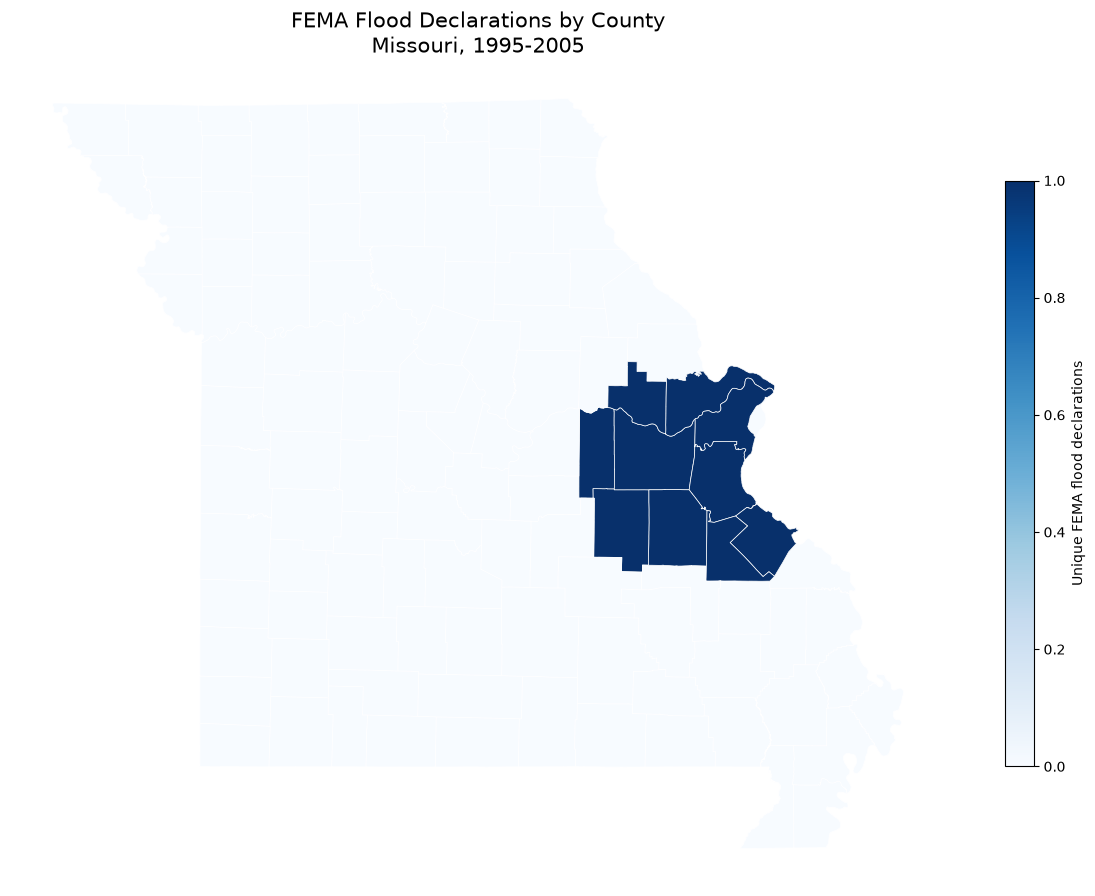

Countys 115
Counties with at least one declaration 10
Total unique disasters 10


,NAME,GEOID,flood_declaration_count
60,Jefferson,29099,1
93,Ste. Genevieve,29186,1
76,Warren,29219,1
35,Gasconade,29073,1
111,St. Louis,29189,1
95,St. Francois,29187,1
14,Crawford,29055,1
65,St. Charles,29183,1
90,Washington,29221,1
47,Franklin,29071,1


In [22]:
STATE = "Missouri"
START_YEAR = 1995
END_YEAR = 2005

project_folder = Path(
    "/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research"
)

floods_path = (
    project_folder
    / "data/intermediate/fema_disaster_declarations_floods_v2.csv"
)

#state name cods
state_fips = {
    "Alabama":"01", "Alaska":"02", "Arizona":"04", "Arkansas":"05",
    "California":"06", "Colorado":"08", "Connecticut":"09",
    "Delaware":"10", "District of Columbia":"11", "Florida":"12",
    "Georgia":"13", "Hawaii":"15", "Idaho":"16", "Illinois":"17",
    "Indiana":"18", "Iowa":"19", "Kansas":"20", "Kentucky":"21",
    "Louisiana":"22", "Maine":"23", "Maryland":"24",
    "Massachusetts":"25", "Michigan":"26", "Minnesota":"27",
    "Mississippi":"28", "Missouri":"29", "Montana":"30",
    "Nebraska":"31", "Nevada":"32", "New Hampshire":"33",
    "New Jersey":"34", "New Mexico":"35", "New York":"36",
    "North Carolina":"37", "North Dakota":"38", "Ohio":"39",
    "Oklahoma":"40", "Oregon":"41", "Pennsylvania":"42",
    "Rhode Island":"44", "South Carolina":"45", "South Dakota":"46",
    "Tennessee":"47", "Texas":"48", "Utah":"49", "Vermont":"50",
    "Virginia":"51", "Washington":"53", "West Virginia":"54",
    "Wisconsin":"55", "Wyoming":"56", "American Samoa":"60",
    "Guam":"66", "Northern Mariana Islands":"69",
    "Puerto Rico":"72", "U.S. Virgin Islands":"78"
}

state_lookup = {name.casefold(): code for name, code in state_fips.items()}
state_input = STATE.strip().casefold()


state_code = state_lookup[state_input]
state_name = state_fips.keys()
STATE = next(name for name in state_fips if name.casefold() == state_input)

floods = pd.read_csv(
    floods_path,
    dtype={
        "fipsStateCode": "string",
        "fipsCountyCode": "string",
        "disasterNumber": "string"
    }
)

floods["declarationDate"] = pd.to_datetime(
    floods["declarationDate"],
    errors="coerce",
    utc=True
)

floods["year"] = floods["declarationDate"].dt.year

floods["fipsStateCode"] = (
    floods["fipsStateCode"].str.strip().str.zfill(2)
)
floods["fipsCountyCode"] = (
    floods["fipsCountyCode"].str.strip().str.zfill(3)
)

# Keep records with county codes not 000
floods = floods[
    floods["fipsStateCode"].notna()
    & floods["fipsCountyCode"].notna()
    & (floods["fipsCountyCode"] != "000")
    & floods["year"].notna()
].copy()

floods["county_geoid"] = (
    floods["fipsStateCode"] + floods["fipsCountyCode"]
)

#filter by state and year
selected = floods[
    (floods["fipsStateCode"] == state_code)
    & (floods["year"] >= START_YEAR)
    & (floods["year"] <= END_YEAR)
].copy()

if selected.empty:
    raise ValueError(
        f"No county-coded FEMA flood records found for "
        f"{STATE}, {START_YEAR}–{END_YEAR}."
    )

# Count each disaster once per county over the selected period
county_counts = (
    selected
    .drop_duplicates(subset=["county_geoid", "disasterNumber"])
    .groupby("county_geoid", as_index=False)
    .agg(
        flood_declaration_count=("disasterNumber", "nunique")
    )
)

# LOAD CENSUS COUNTY BOUNDARIES ## form open api
county_url = (
    "https://www2.census.gov/geo/tiger/TIGER2025/COUNTY/"
    "tl_2025_us_county.zip"
)

counties = gpd.read_file(county_url)
counties["GEOID"] = counties["GEOID"].astype(str).str.zfill(5)

state_counties = counties[
    counties["STATEFP"] == state_code
].copy()

# join counts to counties
county_map = state_counties.merge(
    county_counts,
    left_on="GEOID",
    right_on="county_geoid",
    how="left"
)

county_map["flood_declaration_count"] = (
    county_map["flood_declaration_count"].fillna(0).astype(int)
)

# Map
fig, ax = plt.subplots(figsize=(12, 9))

county_map.plot(
    column="flood_declaration_count",
    ax=ax,
    cmap="Blues",
    legend=True,
    edgecolor="white",
    linewidth=0.5,
    legend_kwds={
        "label": "Unique FEMA flood declarations",
        "shrink": 0.7
    }
)

ax.set_title(
    f"FEMA Flood Declarations by County\n"
    f"{STATE}, {START_YEAR}-{END_YEAR}",
    fontsize=15
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

#summary
print(f"Countys {len(county_map)}")
print(
    "Counties with at least one declaration",
    int((county_map["flood_declaration_count"] > 0).sum())
)
print(
    "Total unique disasters",
    int(county_counts["flood_declaration_count"].sum())
)

display(
    county_map[
        ["NAME", "GEOID", "flood_declaration_count"]
    ]
    .sort_values("flood_declaration_count", ascending=False)
    .head(10)
)


## Fema flood declerations are agregated by county and are only MAJOR (presidentially declared) flooding events (may need to source another dataset)

### Going to investigate NOAA storm event database https://www.ncei.noaa.gov/access/storm-events-database/bulk-data

### Pulling from noaa using duckDB and parquet (api)
##### https://github.com/NCEI-NOAAGov/data-tour-notebooks/blob/github/storm-events-database/SED_Database_Access_Using_DuckDB_and_Parquet.ipynb? (tutorial)

In [23]:

# We use this to indicate we are pulling data with Duckdb
# From a Public Google Cloud Bucket
duckdb.sql("SET s3_endpoint='storage.googleapis.com'")

# Here we set variables that can be reused to the paths for the
# different Storm Events Database datatypes.
details_bucket_path = 'gs://noaa-ncei-ipg/notebooks/data/stormevents/storm_events_database_details/*/*.parquet'
locations_bucket_path = 'gs://noaa-ncei-ipg/notebooks/data/stormevents/storm_events_database_locations.parquet'
fatalities_bucket_path = 'gs://noaa-ncei-ipg/notebooks/data/stormevents/storm_events_database_fatalities.parquet'

In [24]:
# event types in the NOAA Storm Events Database
event_types = duckdb.sql(f"""
    SELECT
        EVENT_TYPE,
        COUNT(*) AS records
    FROM read_parquet(
        '{details_bucket_path}',
        hive_partitioning=true,
        union_by_name=true
    )
    GROUP BY EVENT_TYPE
    ORDER BY records DESC
""").to_df()

display(event_types)

,EVENT_TYPE,records
0,Thunderstorm Wind,570063
1,Hail,423208
2,Flash Flood,110957
3,High Wind,98303
4,Winter Storm,92199
5,Winter Weather,85169
6,Drought,85137
7,Tornado,80996
8,Heavy Snow,76200
9,Flood,70639


##### Loading flood event types, should we exclude coastal and lakeshore flooding and should we keep heavy rainfall

In [25]:
# changeable

state = "MISSOURI"

start_year = 1980
end_year = 1990


# Flood event types

flood_types = [
    "Flood",
    "Flash Flood",
    "Coastal Flood",
    "Lakeshore Flood"
]


flood_query = duckdb.sql(f"""
    SELECT *
    FROM read_parquet(
        '{details_bucket_path}',
        hive_partitioning=true,
        union_by_name=true
    ) AS details
    WHERE
        details.STATE = '{state}'
        AND details.EVENT_TYPE IN {tuple(flood_types)}
        AND details.YEAR BETWEEN {start_year} AND {end_year}
""")

floods_df = flood_query.to_df()

print("State:", state)
print("Years:", start_year, "to", end_year)
print("Flood records:", len(floods_df))
print("Unique flood events:", floods_df["EVENT_ID"].nunique())

print("Event types:")
print(floods_df["EVENT_TYPE"].value_counts())

display(floods_df.head())

State: MISSOURI
Years: 1980 to 1990
Flood records: 0
Unique flood events: 0
Event types:
Series([], Name: count, dtype: int64)


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE,YEAR


### No records checking what years have flood info

In [26]:
flood_history = duckdb.sql(f"""
    SELECT
        YEAR,
        COUNT(*) AS flood_records
    FROM read_parquet(
        '{details_bucket_path}',
        hive_partitioning=true,
        union_by_name=true
    )
    WHERE
        STATE = 'MISSOURI'
        AND EVENT_TYPE IN (
            'Flood',
            'Flash Flood',
            'Coastal Flood',
            'Lakeshore Flood'
        )
    GROUP BY YEAR
    ORDER BY YEAR
""").to_df()

display(flood_history)

,YEAR,flood_records
0,1996,340
1,1997,203
2,1998,448
3,1999,280
4,2000,124
5,2001,366
6,2002,490
7,2003,146
8,2004,362
9,2005,376


### RECORD STARTS IN 1996 need to find dataset with historical data (but noaa is much more spatially comprehensive

#### USGS flood event viewer has more historic records but is based on high water levels so would not be a good options (we want human identified flooding since were comapring to inactive gages?)

#### going to map past 1996 NOAA, agregated into watersheds

## Getting watershed boundaries (USGS Watershed Boundary Dataset (WBD)) 
##### https://www.usgs.gov/national-hydrography/watershed-boundary-dataset

In [27]:
base_url = (
    "https://hydro.nationalmap.gov/arcgis/rest/services/"
    "wbd/MapServer"
)

response = requests.get(
    f"{base_url}/layers",
    params={"f": "json"},
    timeout=60
)

response.raise_for_status()
data = response.json()

for layer in data["layers"]:
    print(layer["id"], layer["name"])


0 WBDLine
1 2-digit HU (Region)
2 4-digit HU (Subregion)
3 6-digit HU (Basin)
4 8-digit HU  (Subbasin)
5 10-digit HU (Watershed)
6 12-digit HU (Subwatershed)
7 14-digit HU
8 16-digit HU


In [28]:
# NOAA Storm Events data you used earlier
details_path = (
    "gs://noaa-ncei-ipg/notebooks/data/stormevents/"
    "storm_events_database_details/*/*.parquet"
)

# Get Missouri flood and flash-flood events for 2000
floods_2000 = duckdb.sql(f"""
    SELECT *
    FROM read_parquet(
        '{details_path}',
        hive_partitioning = true,
        union_by_name = true
    )
    WHERE STATE = 'MISSOURI'
      AND YEAR = 2000
      AND EVENT_TYPE IN ('Flood', 'Flash Flood')
""").df()

print("Number of NOAA event records:", len(floods_2000))
display(floods_2000.head())

Number of NOAA event records: 124


,BEGIN_YEARMONTH,BEGIN_DAY,BEGIN_TIME,END_YEARMONTH,END_DAY,END_TIME,EPISODE_ID,EVENT_ID,STATE,STATE_FIPS,...,END_AZIMUTH,END_LOCATION,BEGIN_LAT,BEGIN_LON,END_LAT,END_LON,EPISODE_NARRATIVE,EVENT_NARRATIVE,DATA_SOURCE,YEAR
0,200005,27,0,200005,28,2359,1096326,5147277,MISSOURI,29,...,,,None,None,None,None,Heavy rainfall affected west central and centr...,,PDC,2000
1,200005,24,2030,200005,24,2300,1095634,5146944,MISSOURI,29,...,,COUNTYWIDE,None,None,None,None,Thunderstorms produced 3 to 5 inches of rain o...,,PDC,2000
2,200005,27,130,200005,27,500,1095017,5146524,MISSOURI,29,...,,SOUTH PORTION,None,None,None,None,"Rainfall of 2 to 3 inches, on top of a 2 to 4 ...",,PDC,2000
3,200005,7,30,200005,7,1730,1095039,5145773,MISSOURI,29,...,,COUNTYWIDE,None,None,None,None,,A thunderstorm complex dropped up to 14 inches...,PDC,2000
4,200005,24,2030,200005,24,2300,1095634,5145572,MISSOURI,29,...,,COUNTYWIDE,None,None,None,None,Thunderstorms produced 3 to 5 inches of rain o...,,PDC,2000


### Looks like they began collecting lat and lon in 2005

### Try to get another spatial unit cz (county and forcast zone)

In [29]:
# Check geographic reporting units in the 2000 Missouri events
print(floods_2000["CZ_TYPE"].value_counts(dropna=False))

display(
    floods_2000[
        ["EVENT_ID", "EVENT_TYPE", "CZ_TYPE", "CZ_NAME", "CZ_FIPS"]
    ].head(10)
)

CZ_TYPE
C    100
Z     24
Name: count, dtype: int64


,EVENT_ID,EVENT_TYPE,CZ_TYPE,CZ_NAME,CZ_FIPS
0,5147277,Flood,Z,HENRY,54
1,5146944,Flash Flood,C,CHRISTIAN,43
2,5146524,Flash Flood,C,BOONE,19
3,5145773,Flash Flood,C,FRANKLIN,71
4,5145572,Flash Flood,C,BARRY,9
5,5145571,Flash Flood,C,STONE,209
6,5146527,Flash Flood,C,MONITEAU,135
7,5146528,Flash Flood,C,OSAGE,151
8,5152132,Flood,Z,CAPE GIRARDEAU,87
9,5153522,Flood,Z,BUCHANAN,20


### matching forcast zones to county based on name and getting missouri counties layer from census for Missouri

In [30]:
county_api = (
    "https://tigerweb.geo.census.gov/arcgis/rest/services/"
    "TIGERweb/tigerWMS_Current/MapServer/82/query"
)

params = {
    "where": "STATE = '29'",
    "outFields": "GEOID,NAME,STATE,COUNTY",
    "returnGeometry": "true",
    "outSR": "4326",
    "f": "geojson"
}

response = requests.get(county_api, params=params, timeout=60)
response.raise_for_status()

geojson = response.json()


missouri_counties = gpd.GeoDataFrame.from_features(
    geojson["features"],
    crs="EPSG:4326"
)

missouri_counties["county_name"] = (
    missouri_counties["NAME"].astype(str).str.strip().str.upper()
)

print("Missouri county polygons:", len(missouri_counties))
display(missouri_counties[["GEOID", "NAME", "county_name"]].head())

Missouri county polygons: 115


,GEOID,NAME,county_name
0,29043,Christian County,CHRISTIAN COUNTY
1,29059,Dallas County,DALLAS COUNTY
2,29197,Schuyler County,SCHUYLER COUNTY
3,29175,Randolph County,RANDOLPH COUNTY
4,29103,Knox County,KNOX COUNTY


#### Matching census counties to c and z names from NOAA Data (counties)

In [31]:
missouri_counties["county_name"] = (
    missouri_counties["NAME"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace(r"\s+COUNTY$", "", regex=True)
    .str.replace(r"\s+CITY$", " CITY", regex=True)
)

events = floods_2000.copy()
events["county_name"] = (
    events["CZ_NAME"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# NOAA reports St. Louis city as "ST. LOUIS (C)"
events.loc[
    events["county_name"] == "ST. LOUIS (C)",
    "county_name"
] = "ST. LOUIS CITY"

county_names = set(missouri_counties["county_name"])
events["name_match"] = events["county_name"].isin(county_names)

print("Total NOAA records:", len(events))
print("Matched by name:", events["name_match"].sum())
print("Unmatched records:", (~events["name_match"]).sum())

display(
    events.loc[
        ~events["name_match"],
        ["CZ_TYPE", "CZ_NAME", "CZ_FIPS", "EVENT_TYPE"]
    ].drop_duplicates()
)

Total NOAA records: 124
Matched by name: 124
Unmatched records: 0


,CZ_TYPE,CZ_NAME,CZ_FIPS,EVENT_TYPE


#### Counting floods within each county

In [51]:
event_counts = (
    events.groupby(["county_name", "CZ_TYPE"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)
for col in ["C", "Z"]:
    if col not in event_counts.columns:
        event_counts[col] = 0

event_counts = event_counts.rename(columns={
    "C": "county_reports",
    "Z": "forecast_zone_reports"
})

#records per location
event_counts["total_reports"] = (
    event_counts["county_reports"]
    + event_counts["forecast_zone_reports"]
)

# counts to geographic boundaries
missouri_flood_map = missouri_counties.merge(
    event_counts,
    on="county_name",
    how="left"
)
count_columns = [
    "county_reports",
    "forecast_zone_reports",
    "total_reports"
]
missouri_flood_map[count_columns] = (
    missouri_flood_map[count_columns].fillna(0).astype(int)
)

print("Total NOAA records:", len(events))
print("Total county reports:", int(events["CZ_TYPE"].eq("C").sum()))
print("Total forecast-zone reports:", int(events["CZ_TYPE"].eq("Z").sum()))
print(
    "Total records counted in summary:",
    missouri_flood_map["total_reports"].sum()
)


Total NOAA records: 124
Total county reports: 100
Total forecast-zone reports: 24
Total records counted in summary: 124


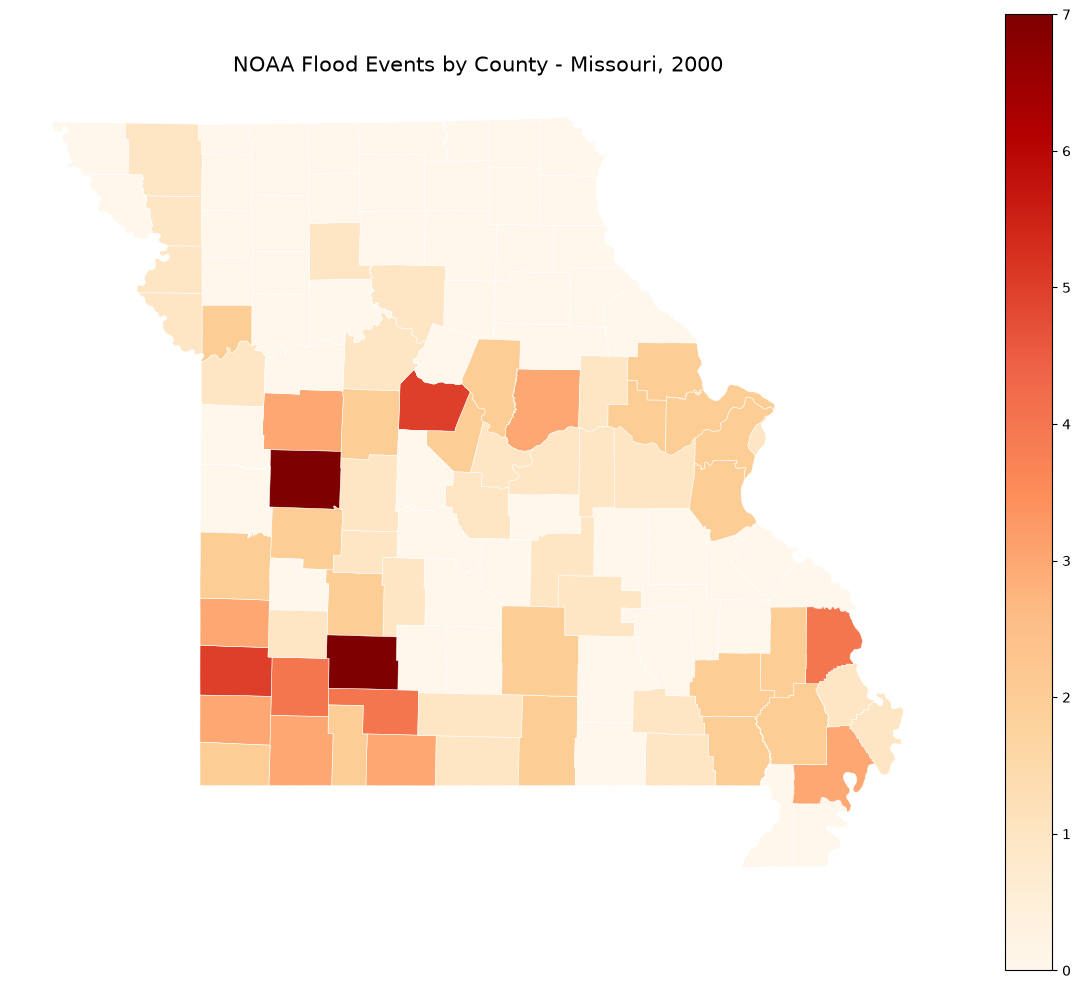

In [33]:
fig, ax = plt.subplots(figsize=(12, 10))

missouri_flood_map.plot(
    column="total_reports",
    cmap="OrRd",
    linewidth=0.4,
    edgecolor="white",
    legend=True,
    ax=ax,
    missing_kwds={"color": "lightgrey"},
    legend_kwds={"label": ""}
)

ax.set_title("NOAA Flood Events by County - Missouri, 2000", fontsize=15)
ax.set_axis_off()

plt.tight_layout()
plt.show()


### aggregating by hcu 8 (using WBD api)

In [44]:
# HUC-8 layer
layer_url = (
    "https://hydro.nationalmap.gov/arcgis/rest/services/"
    "wbd/MapServer/4/query"
)

params = {
    "where": "states LIKE '%MO%'",
    "outFields": "huc8,name,states",
    "returnGeometry": "true",
    "outSR": 26915,
    "f": "json",
    "resultRecordCount": 2000
}

response = requests.get(
    layer_url,
    params=params,
    timeout=120
)

print("Status:", response.status_code)

response.raise_for_status()

data = response.json()

print("HUC-8 records:", len(data.get("features", [])))


Status: 200
HUC-8 records: 67


In [49]:

rows = []
geometries = []

for f in data["features"]:
    rows.append(f["attributes"])

    rings = f["geometry"]["rings"]

    # First ring is the polygon boundary
    geometries.append(Polygon(rings[0]))

huc8 = gpd.GeoDataFrame(
    rows,
    geometry=geometries,
    crs="EPSG:26915"
)

print("HUC-8 watersheds:", len(huc8))
print(huc8[["huc8", "name", "states"]].head())

HUC-8 watersheds: 67
       huc8                              name states
0  08010300  Town of Madrid-Saint Johns Bayou     MO
1  11010001                  Beaver Reservoir  AR,MO
2  11010007                       Upper Black  AR,MO
3  08020302                             Cache  AR,MO
4  10280102                          Thompson  IA,MO


In [52]:
counties = missouri_counties.to_crs("EPSG:26915")
huc8 = huc8.to_crs("EPSG:26915")

overlap = gpd.overlay(
    huc8[["huc8", "geometry"]],
    counties[["county_name", "total_reports", "geometry"]],
    how="intersection"
)
overlap["overlap_area"] = overlap.geometry.area

county_areas = (
    counties.set_index("county_name")
    .geometry.area
)

overlap["county_area"] = overlap["county_name"].map(county_areas)

overlap["estimated_reports"] = (
    overlap["total_reports"]
    * overlap["overlap_area"]
    / overlap["county_area"]
)

huc_counts = (
    overlap
    .groupby("huc8", as_index=False)["estimated_reports"]
    .sum()
)

map_data = huc8.merge(
    huc_counts,
    on="huc8",
    how="left"
)

map_data["estimated_reports"] = (
    map_data["estimated_reports"].fillna(0)
)

print("HUC-8s:", len(map_data))
print("Total estimated reports:",
      map_data["estimated_reports"].sum())

KeyError: "['total_reports'] not in index"

### putting gage activity on top

In [ ]:
state = "Missouri"
year = 2000

input_file = (
    "/Users/sophiameyers/Documents/GitHub/USGS-Gages-Research/"
    "data/intermediate/gages_activity_with_api_locations_recovered.csv"
)

df = pd.read_csv(input_file, dtype={"site": str})

active_rows = []
for _, row in df.iterrows():
    years = str(row["which_years_active"])
    if years in ["nan", "", "None"]:
        continue
    for y in years.split(";"):
        try:
            active_rows.append({
                "site": row["site"],
                "year": int(y)
            })
        except ValueError:
            pass

active_df = pd.DataFrame(active_rows)

state_gages = df[
    df["state_name"].astype(str).str.strip().str.upper() == state.upper()
].copy()

first_year = (
    active_df.groupby("site")["year"].min()
    .rename("first_active_year")
)

state_gages = state_gages.join(first_year, on="site")
state_gages = state_gages[
    state_gages["first_active_year"].notna() &
    (state_gages["first_active_year"] <= year)
].copy()

active_sites = set(
    active_df.loc[active_df["year"] == year, "site"]
)
state_gages["status"] = state_gages["site"].apply(
    lambda site: "Active" if site in active_sites else "Inactive"
)

map_df = state_gages.dropna(
    subset=["latitude", "longitude"]
).drop_duplicates("site")

gages = gpd.GeoDataFrame(
    map_df,
    geometry=gpd.points_from_xy(map_df["longitude"], map_df["latitude"]),
    crs="EPSG:4326"
)

watersheds = map_data.to_crs("EPSG:3857")
gages = gages.to_crs("EPSG:3857")

# Plot watersheds and gage points
fig, ax = plt.subplots(figsize=(12, 10))

watersheds.plot(
    column="estimated_reports",
    cmap="OrRd",
    legend=True,
    edgecolor="white",
    linewidth=0.4,
    ax=ax,
    legend_kwds={"label": ""}
)

gages[gages["status"] == "Active"].plot(
    ax=ax, color="blue", markersize=24,
    label="Active gage", zorder=3
)
gages[gages["status"] == "Inactive"].plot(
    ax=ax, color="red", markersize=24,
    label="Inactive gage", zorder=3
)

ax.set_title(
    f"Missouri HUC-8 Flood Records and USGS Gage Activity, {year}",
    fontsize=14
)
ax.legend()
ax.set_axis_off()
plt.tight_layout()
plt.show()

print("Missouri gages with coordinates:", len(gages))
print("Active:", (gages["status"] == "Active").sum())
print("Inactive:", (gages["status"] == "Inactive").sum())


## How might we go about analyzing the relationship between inactive gages and flooding